# 02 — Phân tích kết quả Lab 2

Notebook đọc các kết quả thực nghiệm đã lưu để:
- So sánh kiến trúc, learning rate, batch size và chiến lược huấn luyện.
- Hiển thị kết quả test của checkpoint được chọn theo validation.
- Đối chiếu với TensorBoard.

Mỗi cấu hình chạy một epoch, seed 42 trên CPU.
Không dùng kết quả này để khẳng định mô hình đã hội tụ.

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Hỗ trợ mở notebook từ gốc dự án hoặc thư mục notebooks.
ROOT = Path.cwd().resolve()
if not (ROOT / "outputs/experiment_summary.csv").is_file():
    ROOT = ROOT.parent

summary_path = ROOT / "outputs/experiment_summary.csv"
assert summary_path.is_file(), f"Không tìm thấy: {summary_path}"

summary = pd.read_csv(summary_path)

# Chỉ phân tích các lượt thực sự có kết quả validation.
completed = summary.dropna(
    subset=["best_val_accuracy", "best_val_loss", "training_time_sec"]
).copy()

assert not completed.empty, "Chưa có lượt thực nghiệm hoàn thành."
assert completed["experiment_name"].is_unique
assert completed["epochs"].eq(1).all(), "Cần kiểm tra lại số epoch."

completed["validation_accuracy_percent"] = (
    completed["best_val_accuracy"] * 100
)
completed["training_time_minutes"] = (
    completed["training_time_sec"] / 60
)

display(completed[[
    "experiment_name", "model_name", "strategy",
    "learning_rate", "batch_size", "epochs",
    "best_val_loss", "validation_accuracy_percent",
    "test_accuracy", "training_time_minutes",
]])

,experiment_name,model_name,strategy,learning_rate,batch_size,epochs,best_val_loss,validation_accuracy_percent,test_accuracy,training_time_minutes
0,E1_vgg16,vgg16,classifier_only,0.0010,32,1,0.524489,82.88,NaN,365.483449
1,E2_densenet121,densenet121,classifier_only,0.0010,32,1,0.346216,87.84,NaN,90.120509
2,E3_learning_rate,densenet121,classifier_only,0.0001,32,1,0.577797,83.44,NaN,88.826972
3,E4_batch_size,densenet121,classifier_only,0.0010,64,1,0.367412,87.16,NaN,91.666124
4,E5_cpu_1epoch,densenet121,finetune_last_layers,0.0001,32,1,0.232135,92.10,0.9181,102.253907


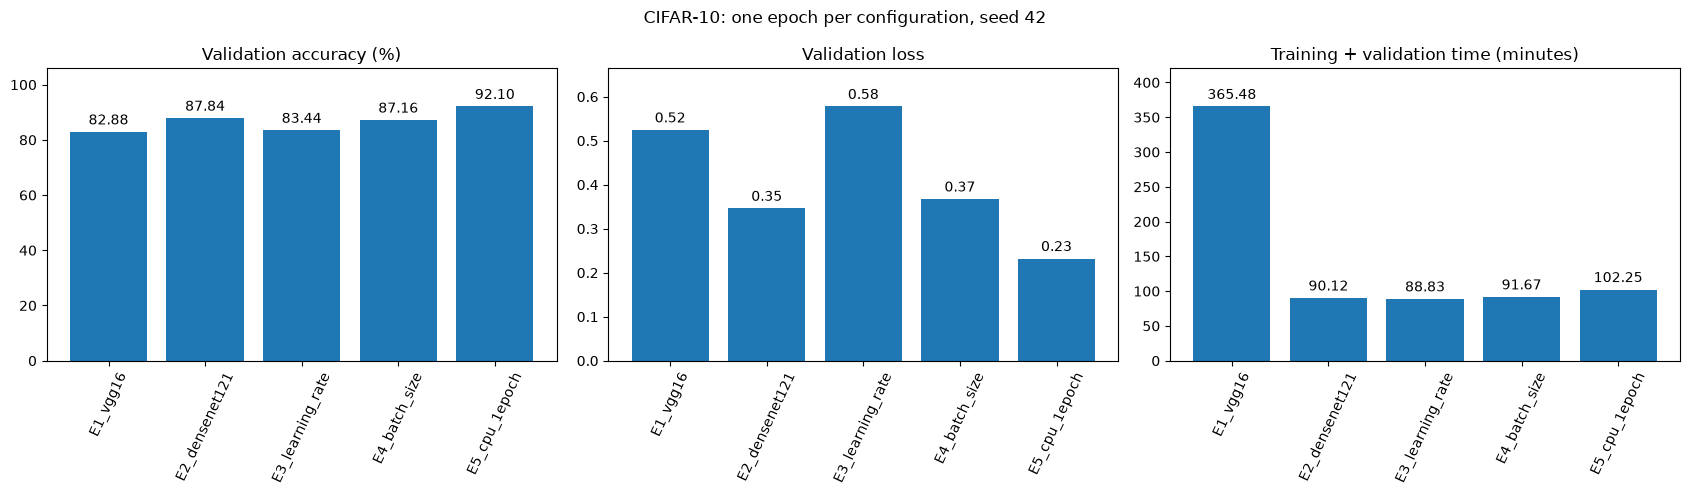

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

names = completed["experiment_name"].tolist()

plots = [
    ("validation_accuracy_percent", "Validation accuracy (%)"),
    ("best_val_loss", "Validation loss"),
    ("training_time_minutes", "Training + validation time (minutes)"),
]

for ax, (column, title) in zip(axes, plots):
    bars = ax.bar(names, completed[column])
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=65)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.margins(y=0.15)

fig.suptitle("CIFAR-10: one epoch per configuration, seed 42")
plt.tight_layout()
plt.show()

In [4]:
selection_path = ROOT / "outputs/best_model_selection.json"
selection = json.loads(selection_path.read_text(encoding="utf-8"))
assert selection["status"] == "selected"

selected_run = selection["selected_run"]
metrics_path = ROOT / "outputs/runs" / selected_run / "metrics.json"
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))

assert metrics["experiment_name"] == selected_run
final_test = metrics["final_test"]

print("Selected run:", selected_run)
print("Test samples:", final_test["test_samples"])
print("Metric source:", final_test["source"])

display(pd.DataFrame({
    "metric": ["test_loss", "accuracy", "precision", "recall", "f1_score"],
    "value": [
        final_test[key]
        for key in ["test_loss", "accuracy", "precision", "recall", "f1_score"]
    ],
}))

Selected run: E5_cpu_1epoch
Test samples: 10000
Metric source: Final test terminal output; rounded to 6 decimal places


,metric,value
0,test_loss,0.245938
1,accuracy,0.918100
2,precision,0.918185
3,recall,0.918100
4,f1_score,0.917776


## Kết luận trong phạm vi thực nghiệm

- E2 đạt validation accuracy 87,84%, cao hơn E1 4,96 điểm phần trăm.
  Hai kiến trúc có classifier và số parameter được huấn luyện khác nhau.
- E2 với learning rate 0.001 cao hơn E3 với 0.0001
  là 4,40 điểm phần trăm sau một epoch.
- E4 với batch 64 thấp hơn E2 với batch 32 là 0,68 điểm phần trăm;
  batch 64 cũng không nhanh hơn trong các lượt đo này.
- E5_cpu_1epoch đạt validation accuracy cao nhất: 92,10%.
  So với E3 cùng learning rate và batch size,
  fine-tuning phần cuối cao hơn 8,66 điểm phần trăm.
- Checkpoint E5 được chọn theo validation, sau đó đạt
  test accuracy 91,81% trên 10.000 ảnh test.
- TensorBoard hiển thị bốn tag Loss/train, Loss/val,
  Accuracy/train và Accuracy/val. Mỗi lượt có một điểm tại epoch 1.

## Hạn chế

Mỗi cấu hình chỉ chạy một epoch và một seed.
Chưa đánh giá độ biến thiên giữa nhiều lần chạy,
chưa kết luận hội tụ và chưa phân tích lỗi theo lớp.
Các metric test được lưu từ terminal với độ chính xác
6 chữ số thập phân.